# 04 - EMT-TF Expression
Unconditional final notebook: score a widened EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX) gated on detectable expression, and overlay the pseudotime-extreme factors on the manifold.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# EMT-TFs read on the manifold; use signatures.h5ad for the oriented layout + pseudotime
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']    # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 3920 | pseudotime range 0.0 -> 9.21


In [ ]:
# widen the panel beyond Snail/Zeb/Twist to include FOXC and PRRX families (Kurten lesson);
# gate on detectable expression (frac_expr > 0.03), rank by pseudotime correlation.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]
    rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nexpressed TFs (frac>0.03): {list(ok.TF)}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.051       0.035      0.011    -0.079    EARLY(root)
  ZEB2      0.039       0.030      0.019    -0.036    EARLY(root)
  ZEB1      0.015       0.011      0.004    -0.030    EARLY(root)
 PRRX2      0.047       0.018      0.023     0.001 LATE(terminus)
TWIST1      0.002       0.000      0.001     0.002 LATE(terminus)
 FOXC1      0.068       0.032      0.033     0.008 LATE(terminus)
 PRRX1      0.016       0.009      0.011     0.015 LATE(terminus)
 FOXC2      0.002       0.000      0.001     0.016 LATE(terminus)
 SNAI1      0.030       0.010      0.024     0.045 LATE(terminus)
TWIST2      0.017       0.002      0.026     0.133 LATE(terminus)

expressed TFs (frac>0.03): ['SNAI2', 'ZEB2', 'PRRX2', 'FOXC1']
derived pair: SNAI2 (early/root) <-> FOXC1 (late/terminus)


overlay thresholds (upper quartile among expressers): {'SNAI2': 0.731, 'FOXC1': 0.791} | cells shown: {'SNAI2': 50, 'FOXC1': 66}
SNAI2: 5.1% expressing; 50 shown; mean pseudotime of shown = 0.39
FOXC1: 6.8% expressing; 66 shown; mean pseudotime of shown = 0.36
saved expression.pdf


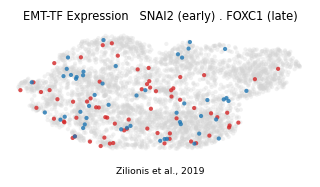

In [ ]:
# DELIVERABLE expression.pdf -- categorical overlay of thresholded expressers on a grey manifold (reference style)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf,late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m=sel[g]; print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f}')
print('saved expression.pdf')
fig